<img src="images/highway2.jpg" width="90%">

# Predictive Analytics & Forecasting
> Executive Master in Business Analytics and AI
> - Project 2026
> - Rita P. Ribeiro - University of Porto | INESC TEC
> - October 2026


## Description
You are part of an analytics team supporting a national road-safety authority. The organization wants to understand how historical highway-accident data can be used to support better road-safety decisions.

# The modeling data

`model_table.csv` covers **1 April 2018 (`ERA_START`) to 31 December 2025**: one row per region per day, with the target (`accidents`) and all features. Training, validation and test are **date ranges of this one table**, split by time, never randomly.

### Training rows start in 2019 Q3

The history features need a full year of data before each quarter's cutoff. For the quarters 2018Q2 to 2019Q2 that year is not complete yet, so some history columns are empty:

| Quarter | Cutoff | `hist_avg_365d` needs data from… | Available? |
|---|---|---|---|
| 2019Q2 | 1 Mar 2019 | 1 Mar 2018 | no: the data starts 1 Apr 2018, so the value is empty |
| **2019Q3** | 1 Jun 2019 | 1 Jun 2018 | **yes: the first complete quarter** |

- **The 2018 Q2–2019 Q2 data is still used:** the history features of later quarters are calculated from it (for example, `hist_avg_365d` for 2019 Q3 is the average from June 2018 to May 2019). Those days are just not training *rows*.
- **Why not train from 2018Q2?** The GLM cannot handle empty values. Starting all three models at 2019 Q3 means they train on exactly the same rows, so the comparison is fair. We give up 2,280 of 13,625 rows (about 17%).

### Training, validation and test

| Part | Period | Rows (region × day) | Used for |
|---|---|---|---|
| **Training** | 2019 Q3 up to each quarter's cutoff | 5,865 before 2023, growing each quarter | fitting the models |
| **Validation** | 2023 Q1 – 2024Q4 (8 quarters) | 3,655 (1,170 weekend/holiday) | comparing models, tuning, ensemble weights |
| **Test** | 2025 Q1 – 2025 Q4 (4 quarters) | 1,825 (585 weekend/holiday) | the final score, used once |

- **Rolling origin:** each quarter is predicted by a model trained only on the days before its cutoff (1 month before the quarter starts). The month between the cutoff and the quarter start is never used, because in real use it has not happened yet.
- **COVID days** (16 March – 30 June 2020) are left out of training.
- **All days are used for training.** The main score is measured on weekends and holidays (the days the planners use), with the all-days score as an extra.

# Task 3 - Modelling

Forecast the number of accidents with victims per region per day, for every weekend day and holiday of the next quarter, 1 month before the quarter starts.

**Contents**
1. Setup
2. How we evaluate
3. Baseline
4. Model 1 - GLM Poisson regression
5. Model 2 - XGBoost
6. Model 3 - Random Forest
7. Comparison
8. Ensemble
9. Final test and interpretation
10. Conclusions and limitations

--------
## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance
from xgboost import XGBRegressor
import os
import seaborn as sns
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score
from sklearn.inspection import DecisionBoundaryDisplay

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data/processed"

# Shared calendar and region functions (src/features.py)
sys.path.append(str(ROOT / "src"))
from features import REGIONS, REGION_EN, build_calendar, get_brazil_holidays, assign_region, haversine_km

# model_table.csv is created in 02_Data_Understanding_Preparation.ipynb, section 6.4
model_table = pd.read_csv(PROCESSED / "model_table.csv", parse_dates=["date"])
model_table.head()

# ---- decisions agreed in Task 1 ----
LEAD_MONTHS = 1         # data cutoff (ref_date) = 1 month before the quarter starts
WINDOW_DAYS = 3         # holiday window = holiday date +/- 3 days
QUARTER_DAYS = 91       # "last quarter" = the 91 days up to the cutoff
ERA_START = pd.Timestamp("2018-04-01")   # start of the modelling period
# Target = accidents with victims = injury (1) or fatal (2) per region per day. Class 0 is excluded. 

REGIONS = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

# plotting: restrained palette, light grid, no top/right spines
BLUE, ORANGE, GREY, DARK = "#2F6DB5", "#D9622B", "#8A8F98", "#222222"
REGION_COLORS = dict(zip(REGIONS, [BLUE, ORANGE, "#1B998B", "#7A5FB5", "#C79A1E"]))
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E3E5E8", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": DARK, "text.color": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "legend.frameon": False, "figure.figsize": (8, 3.6),
})
pd.set_option("display.max_columns", 50, "display.width", 140, "display.float_format", "{:,.3f}".format)

Matplotlib is building the font cache; this may take a moment.


--------
## 2. How we evaluate

- **Split by time, never randomly.**
- **Rolling backtest:** for each past quarter, train on data up to 1 month before the quarter starts, then predict that quarter's weekends and holidays.
- The **last quarters are kept as a final test** and are only used in section 9.
- **Metrics:** MAE, RMSE and Poisson deviance.
- The backtest periods are defined **once** here and reused by every model, so the ensemble can combine predictions for exactly the same days.

Decision:
which days to train on. Our forecast only weekends and holidays, which are 908 of the 2,832 days. I'd suggest:

* Train on all days, with is_weekend and is_holiday as features. 
* That's three times more data, and weekdays still teach the model each region's level and trend.
* Evaluate only on weekends and holidays, because those are the days the planners use.

### 2.1. Define the backtest periods - Train end, cutoff, forecast quarter

In [2]:
model_table.info()

<class 'pandas.DataFrame'>
RangeIndex: 14160 entries, 0 to 14159
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   region                 14160 non-null  str           
 1   date                   14160 non-null  datetime64[us]
 2   accidents              14160 non-null  int64         
 3   region_en              14160 non-null  str           
 4   is_covid               14160 non-null  int64         
 5   month                  14160 non-null  int64         
 6   rain_day_prob          14160 non-null  float64       
 7   heavy_rain_prob        14160 non-null  float64       
 8   avg_daily_precip       14160 non-null  float64       
 9   avg_temp_max           14160 non-null  float64       
 10  avg_humidity_min       14160 non-null  float64       
 11  fire_weather_prob      14160 non-null  float64       
 12  wildfire_season        14160 non-null  int64         
 13  year        

In [3]:
model_table_copy = model_table.copy()

In [4]:
# 2.1.1. Define the train start and the forecast quarters (validation + final test)
TARGET = "accidents"
TRAIN_START = pd.Timestamp("2019-07-01")   # 2019 Q3: first quarter with complete history features

quarters = pd.period_range("2023Q1", "2025Q4", freq="Q")
periods = pd.DataFrame({
    "quarter": quarters.astype(str),
    "q_start": quarters.start_time,
    "q_end": quarters.end_time.normalize(),
})

In [5]:
# 2.1.2. Define the cutoff: 1 month before the quarter starts, training uses only days before it
periods["cutoff"] = periods["q_start"] - pd.DateOffset(months=LEAD_MONTHS)

In [6]:
# 2.1.3. Define the forecast quarters and the final test quarters
# 2023-2024 = validation (backtest, model comparison, tuning), 2025 = final test (used once in section 9)
periods["role"] = np.where(periods["q_start"] < "2025-01-01", "validation", "test")

def split_period(p, features):
    """Train = TRAIN_START up to the cutoff (no COVID days); test = all days of the forecast quarter."""
    d = model_table
    train = d[(d["date"] >= TRAIN_START) & (d["date"] < p.cutoff) & ~d["is_covid"].astype(bool)]
    test = d[(d["date"] >= p.q_start) & (d["date"] <= p.q_end)]
    return train[features], train[TARGET], test[features], test[TARGET]

periods

,quarter,q_start,q_end,cutoff,role
0,2023Q1,2023-01-01,2023-03-31,2022-12-01,validation
1,2023Q2,2023-04-01,2023-06-30,2023-03-01,validation
2,2023Q3,2023-07-01,2023-09-30,2023-06-01,validation
3,2023Q4,2023-10-01,2023-12-31,2023-09-01,validation
4,2024Q1,2024-01-01,2024-03-31,2023-12-01,validation
5,2024Q2,2024-04-01,2024-06-30,2024-03-01,validation
6,2024Q3,2024-07-01,2024-09-30,2024-06-01,validation
7,2024Q4,2024-10-01,2024-12-31,2024-09-01,validation
8,2025Q1,2025-01-01,2025-03-31,2024-12-01,test
9,2025Q2,2025-04-01,2025-06-30,2025-03-01,test


* TARGET, TRAIN_START (1 July 2019, the start of 2019 Q3) and the 12 forecast quarters (2023 Q1 to 2025 Q4), each with its start and end date.
* cutoff for each quarter: 1 month before the quarter starts (for example, 1 Dec 2022 for 2023 Q1).
* 2023-2024 is the validation and 2025 is the test. split_period & features gives training data from TRAIN_START up to the cutoff (leaving COVID days left out) and test data covering every day of that quarters. 

### 2.2. Fill the history features in the COVID gap

COVID days (16 March – 30 June 2020) are left out of the history averages, so two training quarters have empty history features:

| Feature | Empty in | Why | Filled with |
|---|---|---|---|
| `hist_avg_91d` | 2020 Q3 (460 rows) | the 91 days before the 1 June 2020 cutoff are almost all COVID days | `hist_avg_365d` |
| `hist_trend` | 2020 Q3 (460 rows) | it is `hist_avg_91d` / `hist_avg_365d` | 1 = "no trend" (follows from the fill above) |
| `hist_same_q_last_year` | 2021 Q2 (455 rows) | the same quarter last year is 2020 Q2, which was entirely COVID | `hist_avg_365d` |

- **No leakage:** `hist_avg_365d` is the 12-month average before the **same cutoff**, so a planner had that number on the forecast day. Nothing after the cutoff is used, and no average over the whole table is used.
- **Small:** about 4% of the training rows of the last quarter, for each feature.
- **Flag columns:** `hist_91d_filled` and `hist_same_q_filled` are 1 on the filled rows, so the models can treat those rows differently if they behave differently.
- **Same rule for training and test:** the fill is done on `model_table` itself, so every row goes through the same rule. No validation or test quarter has empty history today.
- **Why not drop the rows?** The GLM cannot handle empty values. Dropping 2020 Q3 and 2021 Q2 for the GLM only would make it train on different rows from XGBoost and Random Forest, and the comparison would no longer be fair.

In [7]:
# check of NaN values for the GLM Model 
# Empty values per column in the training rows of one period
p = periods.iloc[-1]   # last period = most training rows
X_train, y_train, X_test, y_test = split_period(p, model_table.columns.drop(TARGET))
na = X_train.isna().sum()
na[na > 0]


holiday_name             10270
days_to_holiday           9240
days_after_holiday        9240
hist_avg_91d               460
hist_same_q_last_year      455
hist_trend                 460
dtype: int64

* Decisions
    * Leave the empty values. For example, using hist_avg_365d where hist_avg_91d is empty. and setting hist_trend to 0;
    * Fill the empty values. For example, using hist_avg_365d where hist_avg_91d is empty, and setting hist_trend to 0.
    * Drop 2020 Q3 and 2021 Q2 from the GLM training rows. But then all three models no longer train on the same rows, which section 1 says they should.

In [8]:
# 2.2.1. Flag and fill the history features that are empty because of the COVID gap

# Flags first: they record which values were empty before the fill
if "hist_91d_filled" not in model_table.columns:
    model_table["hist_91d_filled"] = model_table["hist_avg_91d"].isna().astype(int)
    model_table["hist_same_q_filled"] = model_table["hist_same_q_last_year"].isna().astype(int)

# Fill with the 365-day average at the same cutoff (known on the forecast day, so no leakage)
model_table["hist_avg_91d"] = model_table["hist_avg_91d"].fillna(model_table["hist_avg_365d"])
model_table["hist_same_q_last_year"] = model_table["hist_same_q_last_year"].fillna(model_table["hist_avg_365d"])

# hist_trend = hist_avg_91d / hist_avg_365d, so the filled rows get 1 ("no trend")
model_table["hist_trend"] = model_table["hist_trend"].fillna(model_table["hist_avg_91d"] / model_table["hist_avg_365d"])

In [9]:
# 2.2.2. Check: the filled rows per quarter, and no empty left in the training rows
HIST_COLS = ["hist_avg_91d", "hist_avg_365d", "hist_dayoff_avg_365d", "hist_same_q_last_year", "hist_trend"]
FLAG_COLS = ["hist_91d_filled", "hist_same_q_filled"]

X_train, _, _, _ = split_period(periods.iloc[-1], ["year_quarter"] + HIST_COLS + FLAG_COLS)   # last period = most training rows
print("Empty history values in training:", int(X_train[HIST_COLS].isna().sum().sum()))
print(f"Training rows: {len(X_train):,}")
X_train.groupby("year_quarter")[FLAG_COLS].sum().query("hist_91d_filled > 0 or hist_same_q_filled > 0")

Empty history values in training: 0
Training rows: 10,735


,hist_91d_filled,hist_same_q_filled
year_quarter,,
2020Q3,460,0
2021Q2,0,455


**Result:** no empty history values are left in the training rows. Only 2020 Q3 (`hist_91d_filled`) and 2021 Q2 (`hist_same_q_filled`) are filled, about 4% of the training rows each.

For the report: *History features that fall inside the COVID gap were replaced by the 365-day average available at the forecast cutoff (about 4% of training rows), so no information after the cutoff is used. A flag column marks the filled rows.*

Add `hist_91d_filled` and `hist_same_q_filled` to the feature list of each model.

### 2.3. Metrics and the backtest loop

Defined once and used by the baseline and every model, so all of them are scored on exactly the same rows:

- `score(y, pred)`: MAE, RMSE and Poisson deviance.
- `backtest(fit_predict, features)`: for each validation quarter, trains on the days before its cutoff and predicts every day of the quarter. Returns one row per region and day, with the actual value `y`, the prediction `pred` and `is_day_off` (weekend or holiday).
- `score_table(PREDS)`: scores every model in `PREDS`, on weekends and holidays by default (the days the planners use).
- `PREDS`: each section adds its validation predictions here, for the comparison (section 7) and the ensemble (section 8).

In [10]:
# 2.3.1. Metrics and the backtest loop, shared by the baseline and every model
def score(y, pred):
    """MAE, RMSE and Poisson deviance (the deviance needs predictions above 0)."""
    return pd.Series({
        "MAE": mean_absolute_error(y, pred),
        "RMSE": mean_squared_error(y, pred) ** 0.5,
        "Poisson_dev": mean_poisson_deviance(y, np.clip(pred, 1e-6, None)),
        "n_rows": len(y),
    })

def backtest(fit_predict, features, role="validation"):
    """For every quarter of the given role: train up to its cutoff, predict all its days.
    fit_predict(X_train, y_train, X_test) returns the predictions. One row per region and day."""
    out = []
    for p in periods[periods["role"] == role].itertuples():
        X_tr, y_tr, X_te, y_te = split_period(p, features)
        rows = model_table.loc[X_te.index, ["region", "date", "is_weekend", "is_holiday"]]
        out.append(rows.assign(quarter=p.quarter, y=y_te, pred=np.asarray(fit_predict(X_tr, y_tr, X_te))))
    out = pd.concat(out)
    out["is_day_off"] = (out["is_weekend"] == 1) | (out["is_holiday"] == 1)   # the days the planners use
    return out

def score_table(preds, by=None, day_off_only=True):
    """Scores of each model in preds = {name: backtest output}, on weekends and holidays by default."""
    rows = []
    for name, df in preds.items():
        df = df[df["is_day_off"]] if day_off_only else df
        groups = df.groupby(by) if by else [("all", df)]
        for key, g in groups:
            rows.append(score(g["y"], g["pred"]).rename((name, key)))
    return pd.DataFrame(rows).astype({"n_rows": int}).rename_axis(["model", by or ""])

PREDS = {}   # validation predictions of every model, filled section by section

### 2.4. Features

The GLM gets its own formula in section 4. The tree models (XGBoost, Random Forest) use the `FEATURES` list below.

| Group | Columns | Note |
|---|---|---|
| Region | `region_Norte` … `region_Sul` | one column per region (1/0) |
| Calendar | `month`, `dow` (0 = Monday), `is_weekend`, `is_holiday`, `days_to_holiday`, `days_after_holiday`, holiday window, bridge day, long weekend, school vacation | known in advance |
| Weather | rain, heavy rain, precipitation, temperature, humidity, fire weather, wildfire season | monthly averages per region, the same every year, so known in advance |
| History | the five `hist_*` columns and the two `*_filled` flags | computed at the cutoff |

Left out: `date`, `year`, `day`, `quarter` (`month` covers it), `is_covid` (COVID days are not in training), and the text columns.

In [11]:
# 2.4.1. Feature preparation and the feature list for the tree models
DOW = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
model_table["dow"] = model_table["day_of_week"].map({d: i for i, d in enumerate(DOW)})   # 0 = Monday
for r in REGIONS:
    model_table[f"region_{r}"] = (model_table["region"] == r).astype(int)

REGION_COLS = [f"region_{r}" for r in REGIONS]
CALENDAR_COLS = ["month", "dow", "is_weekend", "is_holiday", "days_to_holiday", "days_after_holiday",
                 "is_holiday_window", "is_bridge_day", "is_long_weekend", "is_school_vacation"]
WEATHER_COLS = ["rain_day_prob", "heavy_rain_prob", "avg_daily_precip", "avg_temp_max", "avg_humidity_min",
                "fire_weather_prob", "wildfire_season"]
FEATURES = REGION_COLS + CALENDAR_COLS + WEATHER_COLS + HIST_COLS + FLAG_COLS
print(len(FEATURES), "features:", FEATURES)

29 features: ['region_Norte', 'region_Nordeste', 'region_Centro-Oeste', 'region_Sudeste', 'region_Sul', 'month', 'dow', 'is_weekend', 'is_holiday', 'days_to_holiday', 'days_after_holiday', 'is_holiday_window', 'is_bridge_day', 'is_long_weekend', 'is_school_vacation', 'rain_day_prob', 'heavy_rain_prob', 'avg_daily_precip', 'avg_temp_max', 'avg_humidity_min', 'fire_weather_prob', 'wildfire_season', 'hist_avg_91d', 'hist_avg_365d', 'hist_dayoff_avg_365d', 'hist_same_q_last_year', 'hist_trend', 'hist_91d_filled', 'hist_same_q_filled']


--------
## 3. Baseline

The Baseline is a  simple rule to beat. A model is only worth using if it does better than this threshold.

**Main baseline (`baseline_dayoff_365d`):** for each region, predict the average accidents per weekend/holiday day over the 365 days before the cutoff (`hist_dayoff_avg_365d`). It needs no training and uses only data known on the forecast day.

Two other simple rules, for context:
- `naive_all_days_365d`: the average over all days of the last 365 days (`hist_avg_365d`).
- `naive_same_q_last_year`: the average of the same quarter one year earlier (`hist_same_q_last_year`).

Scored on the 8 validation quarters (2023 Q1 – 2024 Q4). The final test quarters are not touched.

#### 3.1. Predict with the baseline rules

- **Stage:** prediction only. No training and no tuning: each rule copies a history feature that was computed at the cutoff.
- **Data:** the 8 validation quarters (2023 Q1 – 2024 Q4).
- **Output:** `PREDS["baseline_dayoff_365d"]`, `PREDS["naive_all_days_365d"]` and `PREDS["naive_same_q_last_year"]`.

In [12]:
# 3.1. Baseline rules: no training, just a history feature known at the cutoff
BASELINES = {
    "baseline_dayoff_365d": "hist_dayoff_avg_365d",   # main baseline: same day type, last 365 days
    "naive_all_days_365d": "hist_avg_365d",           # all days, last 365 days
    "naive_same_q_last_year": "hist_same_q_last_year",  # same quarter one year earlier (seasonality)
}
for name, col in BASELINES.items():
    PREDS[name] = backtest(lambda X_tr, y_tr, X_te, col=col: X_te[col], [col])

score_table(PREDS)

,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.217,1.546,1.148,1170
naive_all_days_365d,all,1.197,1.556,1.165,1170
naive_same_q_last_year,all,1.200,1.565,1.184,1170


#### 3.2. Score per region and on all days

- **Stage:** evaluation. No new predictions: the same predictions, scored per region (weekends and holidays) and on all days.

In [13]:
# 3.2. Scores per region (weekends and holidays) and on all days
display(score_table(PREDS, by="region"))
score_table(PREDS, day_off_only=False)

MAE  RMSE  Poisson_dev  n_rows
model                  region                                       
baseline_dayoff_365d   Centro-Oeste 0.964 1.157        1.154     234
                       Nordeste     1.371 1.751        1.158     234
                       Norte        0.733 0.907        1.212     234
                       Sudeste      1.531 1.888        1.142     234
                       Sul          1.487 1.778        1.073     234
naive_all_days_365d    Centro-Oeste 0.958 1.178        1.194     234
                       Nordeste     1.377 1.796        1.222     234
                       Norte        0.727 0.905        1.211     234
                       Sudeste      1.470 1.867        1.118     234
                       Sul          1.454 1.787        1.082     234
naive_same_q_last_year Centro-Oeste 0.957 1.187        1.214     234
                       Nordeste     1.378 1.821        1.263     234
                       Norte        0.726 0.916        1.241     234
                       Sudeste      1.469 1.866        1.117     234
                       Sul          1.468 1.791        1.087     234

,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.203,1.532,1.167,3655
naive_all_days_365d,all,1.166,1.525,1.158,3655
naive_same_q_last_year,all,1.168,1.532,1.169,3655


#### 3.3. Result

- **Stage:** evaluation on the validation quarters (1,170 weekend/holiday rows).

| Rule | MAE | RMSE | Poisson deviance |
|---|---|---|---|
| **`baseline_dayoff_365d`** | 1.217 | **1.546** | **1.148** |
| `naive_all_days_365d` | **1.197** | 1.556 | 1.165 |
| `naive_same_q_last_year` | 1.200 | 1.565 | 1.184 |

- **The three rules are close.** The day-off rule is best on RMSE and Poisson deviance. The all-days rule is 0.02 better on MAE, because MAE rewards predicting slightly low on skewed counts. Poisson deviance is the metric made for counts, so `baseline_dayoff_365d` is the one to beat: **MAE 1.217, RMSE 1.546, Poisson deviance 1.148**.
- **The baseline lags when accidents rise.** It is an average of the past year: in 2023 Q4 the actual average was 2.53 accidents per weekend/holiday day, the baseline predicted 2.20. The models have `hist_trend` and calendar features that can pick up part of this.
- **Expect small gains.** A region has about 2.3 accidents per weekend/holiday day. If the counts were Poisson, even a perfect forecast of the daily rate would have an RMSE of about √2.33 ≈ 1.53, close to the baseline's 1.546. Most of the day-to-day variation is chance, so a model that beats the baseline by a few percent is already a real improvement.

--------
## 4. Model 1 - GLM Poisson regression

Poisson regression with a log link: the prediction is a rate, and each feature multiplies it by a factor (`exp(coef)`).

**Formula**

`accidents ~ log(hist_avg_365d) + log(hist_trend) + day of week + month + holiday features + filled flags`

- **Level: `log(hist_avg_365d)`** (the region's average per day over the last 365 days), not a fixed effect per region. With a log link, a coefficient of 1 means "the forecast moves 1-to-1 with the region's recent level". The level then follows the data at each cutoff, instead of being fixed for the whole training period. We use the all-days average because it is based on 3 times more days than the weekend/holiday average, so it is less noisy; the day-of-week terms add the weekend effect.
- **`log(hist_trend)`**: was the last quarter above or below the yearly level?
- **Calendar:** day of week, month, holiday, holiday window, bridge day, long weekend, school vacation.
- The weather columns are left out: they are monthly averages per region, and the month terms already cover most of them.

Check whether the counts are more spread out than a Poisson model allows (overdispersion). If they are, also try a negative binomial model.

In [14]:
model_table

,region,date,accidents,region_en,is_covid,month,rain_day_prob,heavy_rain_prob,avg_daily_precip,avg_temp_max,avg_humidity_min,fire_weather_prob,wildfire_season,year,quarter,day,day_of_week,is_weekend,holiday_name,is_holiday,days_to_holiday,days_after_holiday,is_holiday_window,is_bridge_day,is_long_weekend,is_school_vacation,year_quarter,hist_avg_91d,hist_avg_365d,hist_dayoff_avg_365d,hist_same_q_last_year,hist_trend,hist_91d_filled,hist_same_q_filled,dow,region_Norte,region_Nordeste,region_Centro-Oeste,region_Sudeste,region_Sul
0,Norte,2018-04-01,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,1,Sunday,1,NaN,0,NaN,2.000,1,0,1,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1,6,1,0,0,0,0
1,Norte,2018-04-02,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,2,Monday,0,NaN,0,NaN,3.000,1,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1,0,1,0,0,0,0
2,Norte,2018-04-03,0,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,3,Tuesday,0,NaN,0,NaN,NaN,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1,1,1,0,0,0,0
3,Norte,2018-04-04,1,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,4,Wednesday,0,NaN,0,NaN,NaN,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1,2,1,0,0,0,0
4,Norte,2018-04-05,1,North,0,4,0.798,0.082,8.459,29.280,69.496,0.003,0,2018,2,5,Thursday,0,NaN,0,NaN,NaN,0,0,0,0,2018Q2,NaN,NaN,NaN,NaN,NaN,1,1,3,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14155,Sul,2025-12-27,5,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,27,Saturday,1,NaN,0,NaN,2.000,1,0,1,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0,5,0,0,0,0,1
14156,Sul,2025-12-28,1,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,28,Sunday,1,NaN,0,3.000,3.000,1,0,1,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0,6,0,0,0,0,1
14157,Sul,2025-12-29,4,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,29,Monday,0,NaN,0,2.000,NaN,1,0,0,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0,0,0,0,0,0,1
14158,Sul,2025-12-30,3,South,0,12,0.513,0.069,5.359,26.986,59.865,0.015,0,2025,4,30,Tuesday,0,NaN,0,1.000,NaN,1,0,0,1,2025Q4,3.264,3.419,3.403,3.674,0.955,0,0,1,0,0,0,0,1


#### 4.1. Train and predict

- **Stage:** training + prediction (rolling backtest). There is no tuning loop: this cell runs the formula above. The formula was chosen by comparing a few versions on the validation quarters (see the result below).
- **How:** for each of the 8 validation quarters, the GLM is fitted on the training days before that quarter's cutoff (from 2019 Q3, without COVID days), then predicts every day of the quarter. So the GLM is fitted 8 times, each time on a bit more data.
- **Output:** `PREDS["glm_poisson"]`, and the 8 fitted models in `GLM_FITS`.

In [15]:
# 4.1. GLM Poisson on the backtest periods
GLM_FORMULA = ("accidents ~ np.log(hist_avg_365d) + np.log(hist_trend) + C(day_of_week) + C(month)"
               " + is_holiday + is_holiday_window + is_bridge_day + is_long_weekend + is_school_vacation"
               " + hist_91d_filled + hist_same_q_filled")
GLM_COLS = ["hist_avg_365d", "hist_trend", "day_of_week", "month", "is_holiday", "is_holiday_window",
            "is_bridge_day", "is_long_weekend", "is_school_vacation", "hist_91d_filled", "hist_same_q_filled"]
GLM_FITS = []   # one fitted model per validation quarter, for the checks below

def fit_predict_glm(X_tr, y_tr, X_te):
    m = smf.glm(GLM_FORMULA, data=X_tr.assign(accidents=y_tr), family=sm.families.Poisson()).fit()
    GLM_FITS.append(m)
    return m.predict(X_te)

PREDS["glm_poisson"] = backtest(fit_predict_glm, GLM_COLS)
score_table({k: PREDS[k] for k in ["baseline_dayoff_365d", "glm_poisson"]})

,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.217,1.546,1.148,1170
glm_poisson,all,1.196,1.523,1.121,1170


#### 4.2. Check overdispersion

- **Stage:** model check. No new training: it uses the 8 models fitted in 4.1.
- **How:** for each model, Pearson χ² divided by the residual degrees of freedom. About 1 means the Poisson assumption holds. Clearly above 1 (for example 1.5) means the counts are more spread out than Poisson allows, and a negative binomial model should be tried.

In [16]:
# 4.2. Overdispersion check: Pearson chi2 / degrees of freedom, about 1 for Poisson data, clearly above 1 if overdispersed
dispersion = pd.Series([m.pearson_chi2 / m.df_resid for m in GLM_FITS],
                       index=periods.loc[periods["role"] == "validation", "quarter"], name="dispersion")
dispersion.round(3).to_frame().T

quarter,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4
dispersion,1.004,1.005,1.017,1.023,1.021,1.016,1.017,1.021


#### 4.3. Interpret the coefficients

- **Stage:** interpretation. No new training: it uses the last of the 8 models (trained up to 1 Sep 2024, used to forecast 2024 Q4).
- **How to read it:**
  - `rate_ratio` = exp(coef): 1.10 means 10% more accidents, 0.90 means 10% fewer, compared to the reference (Friday for the day of week, January for the month).
  - For the `log()` terms, read `coef`: 1% higher level means `coef` % more accidents.
  - If the confidence interval (`ci_low` to `ci_high`) includes 1, or `p_value` is above 0.05, the effect is not clear.

In [17]:
# 4.3. Coefficients of the last validation fit (trained up to 1 Sep 2024)
# rate_ratio = exp(coef): 1.10 = 10% more accidents, 0.90 = 10% fewer.
# For the log() terms read coef instead: 1% higher level -> coef % more accidents
glm = GLM_FITS[-1]
ci = glm.conf_int()
coefs = pd.DataFrame({
    "coef": glm.params,
    "rate_ratio": np.exp(glm.params),
    "ci_low": np.exp(ci[0]),
    "ci_high": np.exp(ci[1]),
    "p_value": glm.pvalues,
}).drop(index="Intercept")
coefs.round(3)

,coef,rate_ratio,ci_low,ci_high,p_value
C(day_of_week)[T.Monday],-0.122,0.885,0.839,0.933,0.000
C(day_of_week)[T.Saturday],0.037,1.037,0.985,1.092,0.162
C(day_of_week)[T.Sunday],0.028,1.028,0.977,1.083,0.290
C(day_of_week)[T.Thursday],-0.272,0.762,0.721,0.805,0.000
C(day_of_week)[T.Tuesday],-0.214,0.808,0.765,0.853,0.000
C(day_of_week)[T.Wednesday],-0.222,0.801,0.758,0.846,0.000
C(month)[T.2],-0.053,0.948,0.839,1.071,0.394
C(month)[T.3],-0.059,0.943,0.836,1.063,0.335
C(month)[T.4],-0.031,0.969,0.853,1.101,0.629
C(month)[T.5],0.005,1.005,0.888,1.137,0.935


#### 4.4. Result

- **Stage:** evaluation on the validation quarters (1,170 weekend/holiday rows).

| Model | MAE | RMSE | Poisson deviance |
|---|---|---|---|
| `baseline_dayoff_365d` | 1.217 | 1.546 | 1.148 |
| **`glm_poisson`** | **1.196** | **1.523** | **1.121** |

- **The GLM beats the baseline on all three metrics**, by about 2% on the Poisson deviance.
- **No overdispersion:** the dispersion is between 1.00 and 1.02 in every quarter, so the Poisson assumption holds and a negative binomial model is not needed. (A negative binomial fit gave the same predictions.)
- **Coefficients** (last fit):
  - `log(hist_avg_365d)`: coef 0.99, so the forecast follows the region's recent level 1-to-1.
  - **Day of week:** Monday to Thursday have 12–24% fewer accidents than Friday; Saturday and Sunday are about the same as Friday.
  - **December** has about 13% more accidents than January. The other months and the holiday features are not significant once the day of week is in the model.
  - `hist_91d_filled` is 0.90: in 2020 Q3 there were about 10% fewer accidents than the filled history suggested (traffic was still recovering from COVID).
- **Tried and dropped:** a fixed effect per region instead of `log(hist_avg_365d)` (Poisson deviance 1.137), and adding the weather columns (no gain).

--------
## 5. Model 2 - XGBoost

`XGBRegressor(objective="count:poisson")`: gradient-boosted trees with a Poisson loss, so the predictions are positive rates, like the GLM. It uses all the `FEATURES` (section 2.4) and handles the empty `days_to_holiday` / `days_after_holiday` values itself.

**Tuning** on the validation quarters: tree depth and number of trees. The validation score of the chosen settings is therefore a bit optimistic; the final test (section 9) gives the honest score.

#### 5.1. Tune

- **Stage:** tuning. 8 settings: tree depth (2, 3, 4, 6) × number of trees (300, 600). The other settings are fixed: learning rate 0.03, 80% of the rows and columns per tree, at least 5 rows per leaf.
- **How:** each setting runs the full rolling backtest (8 settings × 8 quarters = 64 models, about 30 seconds) and is scored on the weekend/holiday validation rows.
- **Choice:** the setting with the lowest Poisson deviance.
- **Note:** the validation quarters are used both to choose the settings and to score them, so the score of the chosen setting is a bit optimistic. The final test (section 9) gives the honest score.

In [18]:
# 5.1. Tune XGBoost on the validation quarters: tree depth x number of trees
def make_xgb(max_depth, n_estimators, learning_rate=0.03):
    def fit_predict(X_tr, y_tr, X_te):
        m = XGBRegressor(objective="count:poisson", max_depth=max_depth, n_estimators=n_estimators,
                         learning_rate=learning_rate, subsample=0.8, colsample_bytree=0.8,
                         min_child_weight=5, random_state=42, n_jobs=-1)
        XGB_FITS.append(m.fit(X_tr, y_tr))
        return m.predict(X_te)
    return fit_predict

XGB_GRID = [{"max_depth": d, "n_estimators": n} for d in [2, 3, 4, 6] for n in [300, 600]]
xgb_runs = {}
for params in XGB_GRID:
    XGB_FITS = []
    xgb_runs[(params["max_depth"], params["n_estimators"])] = (backtest(make_xgb(**params), FEATURES), XGB_FITS)

xgb_tuning = score_table({k: v[0] for k, v in xgb_runs.items()}).droplevel(1)
xgb_tuning.index = pd.MultiIndex.from_tuples(xgb_tuning.index, names=["max_depth", "n_estimators"])
xgb_tuning.sort_values("Poisson_dev")

MAE  RMSE  Poisson_dev  n_rows
max_depth n_estimators                                 
2         300          1.203 1.527        1.128    1170
          600          1.199 1.526        1.129    1170
3         300          1.201 1.527        1.130    1170
          600          1.199 1.530        1.135    1170
4         300          1.201 1.532        1.138    1170
          600          1.203 1.539        1.149    1170
6         300          1.207 1.546        1.159    1170
          600          1.213 1.559        1.183    1170

#### 5.2. Train with the chosen settings and look at feature importance

- **Stage:** training (with the chosen settings) + interpretation. The backtest of the best setting already ran in 5.1, so its predictions and its 8 models are reused here, not trained again.
- **Output:** `PREDS["xgboost"]`, and the 8 fitted models in `XGB_FITS`.
- **Feature importance:** from the last of the 8 models (trained up to 1 Sep 2024). Gain = how much a feature improves the loss when the trees use it, as a share of the total.
- The final test (section 9) trains the same settings again, on the data before each test quarter's cutoff.

In [19]:
# 5.2. Keep the best settings (lowest Poisson deviance) and look at the feature importance of its last fit
best = xgb_tuning["Poisson_dev"].idxmin()
PREDS["xgboost"], XGB_FITS = xgb_runs[best]
print("Best settings: max_depth = %d, n_estimators = %d" % best)
display(score_table({k: PREDS[k] for k in ["baseline_dayoff_365d", "glm_poisson", "xgboost"]}))

# Gain = how much each feature improves the loss when the trees use it
importance = pd.Series(XGB_FITS[-1].get_booster().get_score(importance_type="gain"), name="gain")
(importance / importance.sum()).sort_values(ascending=False).head(15).round(3).to_frame()

Best settings: max_depth = 2, n_estimators = 300


,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.217,1.546,1.148,1170
glm_poisson,all,1.196,1.523,1.121,1170
xgboost,all,1.203,1.527,1.128,1170


,gain
hist_avg_91d,0.351
hist_avg_365d,0.199
region_Nordeste,0.131
hist_dayoff_avg_365d,0.073
region_Centro-Oeste,0.055
region_Norte,0.052
hist_same_q_last_year,0.038
dow,0.021
is_weekend,0.010
region_Sudeste,0.009


#### 5.3. Result

- **Stage:** evaluation on the validation quarters (1,170 weekend/holiday rows).

| Model | MAE | RMSE | Poisson deviance |
|---|---|---|---|
| `baseline_dayoff_365d` | 1.217 | 1.546 | 1.148 |
| **`glm_poisson`** | **1.196** | **1.523** | **1.121** |
| `xgboost` (depth 2, 300 trees) | 1.203 | 1.527 | 1.128 |

- **Shallow trees win.** Depth 2 is best; depth 6 is worse than the baseline (Poisson deviance 1.159–1.183). The signal is mostly the region's level and the day of week, and deeper trees start fitting noise.
- **XGBoost beats the baseline, but not the GLM.** With this little signal, the simpler model is as good or better.
- **Feature importance** (share of gain, last fit): the history features about 66% (`hist_avg_91d` 35%, `hist_avg_365d` 20%), the region columns about 25%, day of week and weekend about 3%, each weather column below 1%. The same story as the GLM: the recent level of each region carries most of the information.
- Depth 2 is the smallest depth tried. A depth-1 model could be tried too, but the gain would be small.

--------
## 6. Model 3 - Random Forest

`RandomForestRegressor(criterion="poisson")`

Poisson criterion, so the trees split on the loss made for counts. It uses the same `FEATURES` (section 2.4) and the same `backtest()` as XGBoost, so all models are scored on exactly the same rows.

**Two choices specific to the Random Forest:**
- **Empty `days_to_holiday` / `days_after_holiday`** mean "no holiday within 3 days". That is information, not a missing value, so they are coded as **4** ("more than 3 days away"). Filling with the mean (≈1.4) would put every normal day 1 day from a holiday.
- **Target as a ratio to the region's level.** Trees cannot predict outside the range of values they saw in training, so a rising region would be under-forecast. The forest learns `accidents / hist_avg_365d` (e.g. "a long weekend is 1.15× the usual level"), and the prediction is multiplied back by the level known at the cutoff. Both versions are compared below.

#### 6.1. Tune

- **Stage:** tuning. 6 settings: minimum rows per leaf (5, 20, 50) × share of features tried at each split (0.33, 0.6), with 200 trees and the direct count target.
- **How:** each setting runs the full rolling backtest (6 settings × 8 quarters = 48 forests, about 1–2 minutes) and is scored on the weekend/holiday validation rows.
- **Choice:** the setting with the lowest Poisson deviance. The settings are tuned with the direct count target; the target itself is chosen in 6.2. As for XGBoost, the validation score of the chosen setting is a bit optimistic; the final test (section 9) gives the honest score.

In [20]:
# 6.1. Tune the Random Forest on the validation quarters: leaf size x features per split
def prepare_rf(X):
    """Empty days_to/after_holiday = no holiday within 3 days -> coded as 4."""
    return X.fillna({"days_to_holiday": 4, "days_after_holiday": 4})

def make_rf(min_samples_leaf, max_features, n_estimators=200, target="count"):
    def fit_predict(X_tr, y_tr, X_te):
        m = RandomForestRegressor(n_estimators=n_estimators, criterion="poisson", min_samples_leaf=min_samples_leaf,
                                  max_features=max_features, n_jobs=-1, random_state=42)
        if target == "ratio":   # learn accidents relative to the region's level known at the cutoff
            m.fit(prepare_rf(X_tr), y_tr / X_tr["hist_avg_365d"])
            pred = m.predict(prepare_rf(X_te)) * X_te["hist_avg_365d"].to_numpy()
        else:
            m.fit(prepare_rf(X_tr), y_tr)
            pred = m.predict(prepare_rf(X_te))
        RF_FITS.append(m)
        return pred
    return fit_predict

RF_GRID = [{"min_samples_leaf": l, "max_features": f} for l in [5, 20, 50] for f in [0.33, 0.6]]
rf_runs = {}
for params in RF_GRID:
    RF_FITS = []
    rf_runs[(params["min_samples_leaf"], params["max_features"])] = backtest(make_rf(**params), FEATURES)

rf_tuning = score_table(rf_runs).droplevel(1)
rf_tuning.index = pd.MultiIndex.from_tuples(rf_tuning.index, names=["min_samples_leaf", "max_features"])
rf_tuning.sort_values("Poisson_dev")

MAE  RMSE  Poisson_dev  n_rows
min_samples_leaf max_features                                 
50               0.600        1.207 1.535        1.133    1170
                 0.330        1.207 1.535        1.134    1170
20               0.600        1.205 1.536        1.137    1170
                 0.330        1.206 1.538        1.139    1170
5                0.330        1.207 1.546        1.155    1170
                 0.600        1.213 1.551        1.162    1170

#### 6.2. Count or ratio target, with the chosen settings

- **Stage:** training (chosen settings, 500 trees) + comparison of the two targets on the validation quarters.
- **Output:** `PREDS["random_forest"]` (the target with the lower Poisson deviance), and the 8 fitted forests in `RF_FITS`.

In [21]:
# 6.2. Chosen settings, 500 trees: direct count vs ratio to the region's level
best_rf = rf_tuning["Poisson_dev"].idxmin()
print("Best settings: min_samples_leaf = %d, max_features = %.2f" % best_rf)
rf_target_runs, rf_target_fits = {}, {}
for target in ["count", "ratio"]:
    RF_FITS = []
    rf_target_runs[f"random_forest_{target}"] = backtest(
        make_rf(*best_rf, n_estimators=500, target=target), FEATURES)
    rf_target_fits[target] = RF_FITS
display(score_table({**{k: PREDS[k] for k in ["baseline_dayoff_365d", "glm_poisson", "xgboost"]}, **rf_target_runs}))

RF_TARGET = min(["count", "ratio"],
                key=lambda t: score_table({t: rf_target_runs[f"random_forest_{t}"]})["Poisson_dev"].iloc[0])
PREDS["random_forest"], RF_FITS = rf_target_runs[f"random_forest_{RF_TARGET}"], rf_target_fits[RF_TARGET]
print("Chosen target:", RF_TARGET)

Best settings: min_samples_leaf = 50, max_features = 0.60


,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.217,1.546,1.148,1170
glm_poisson,all,1.196,1.523,1.121,1170
xgboost,all,1.203,1.527,1.128,1170
random_forest_count,all,1.208,1.535,1.133,1170
random_forest_ratio,all,1.197,1.528,1.130,1170


Chosen target: ratio


#### 6.3. Feature importance

- **Stage:** interpretation. No new training: the 8 forests from 6.2, each on its own validation quarter.
- **How:** permutation importance: shuffle one feature at a time and measure how much the Poisson deviance gets worse. Each of the 8 forests is scored **only on the weekend/holiday days of the quarter it forecast**, which it never saw in training (the cell checks this with an `assert`). The 2025 test quarters are not used here.
- **Note on the ratio target:** the region's level (`hist_avg_365d`) also multiplies the prediction, and that part is not shuffled here. So this chart shows what drives the *ratio* (the day-to-day pattern around the level); the level itself is the biggest driver of the count, as in the GLM (coef 0.99).

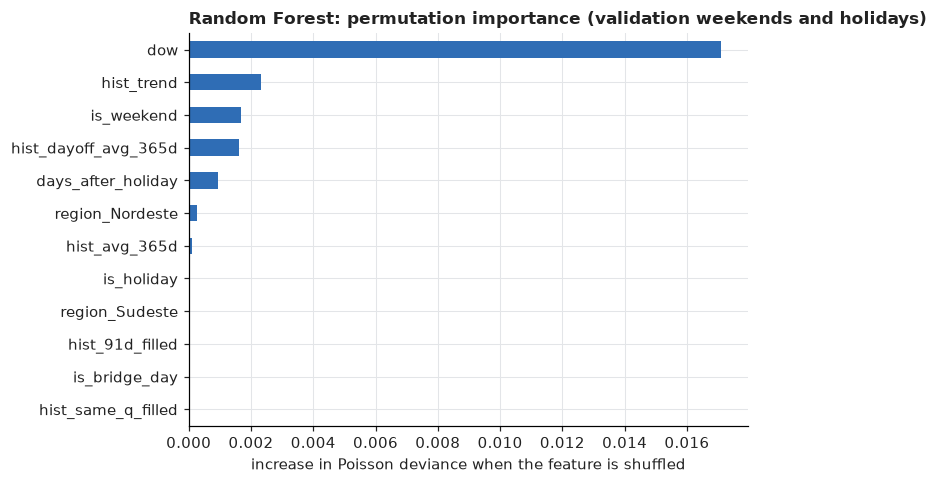

,deviance_increase
dow,0.017
hist_trend,0.002
is_weekend,0.002
hist_dayoff_avg_365d,0.002
days_after_holiday,0.001
region_Nordeste,0.000
hist_avg_365d,0.000
is_holiday,0.000
region_Sudeste,0.000
hist_91d_filled,-0.000


In [22]:
# 6.3. Permutation importance of the 8 validation forests, each on its OWN quarter's weekends and holidays
def rf_permutation_importance(forests, n_repeats=5, seed=42):
    """Shuffle one feature at a time and measure how much the Poisson deviance gets worse.
    Each forest is scored only on the quarter it forecast, never on rows it was trained on."""
    rng = np.random.default_rng(seed)
    val_periods = periods[periods["role"] == "validation"]
    assert len(forests) == len(val_periods), "one forest per validation quarter expected"
    worse = {col: [] for col in FEATURES}
    for q, forest in zip(val_periods.itertuples(), forests):
        X_tr, _, X_q, y_q = split_period(q, FEATURES)
        # out-of-sample check: every training day is before the cutoff, every scored day is in the quarter
        assert model_table.loc[X_tr.index, "date"].max() < q.cutoff < q.q_start <= model_table.loc[X_q.index, "date"].min()
        off = ((X_q["is_weekend"] == 1) | (X_q["is_holiday"] == 1)).to_numpy()
        X_q, y_q = X_q[off], y_q[off].to_numpy()
        level = X_q["hist_avg_365d"].to_numpy() if RF_TARGET == "ratio" else 1.0
        predict = lambda X: np.clip(forest.predict(prepare_rf(X)) * level, 1e-6, None)
        base_dev = mean_poisson_deviance(y_q, predict(X_q))
        for col in FEATURES:
            for _ in range(n_repeats):
                X_perm = X_q.copy()
                X_perm[col] = rng.permutation(X_perm[col].to_numpy())
                worse[col].append(mean_poisson_deviance(y_q, predict(X_perm)) - base_dev)
    return pd.Series({c: np.mean(v) for c, v in worse.items()}, name="deviance_increase").sort_values(ascending=False)

rf_importance = rf_permutation_importance(RF_FITS)

ax = rf_importance.head(12)[::-1].plot.barh(color=BLUE, figsize=(7, 4.5))
ax.set(title="Random Forest: permutation importance (validation weekends and holidays)",
       xlabel="increase in Poisson deviance when the feature is shuffled")
plt.tight_layout(); plt.show()
rf_importance.head(12).round(4).to_frame()

#### 6.4. Result

- **Stage:** evaluation on the validation quarters (1,170 weekend/holiday rows).

| Model | MAE | RMSE | Poisson deviance |
|---|---|---|---|
| `baseline_dayoff_365d` | 1.217 | 1.546 | 1.148 |
| **`glm_poisson`** | **1.196** | **1.523** | **1.121** |
| `xgboost` (depth 2, 300 trees) | 1.203 | 1.527 | 1.128 |
| `random_forest`, count target | 1.208 | 1.535 | 1.133 |
| `random_forest`, ratio target (chosen) | 1.197 | 1.528 | 1.130 |

- **Large leaves win.** Leaves of 20–50 rows are within 0.006 Poisson deviance of each other; leaves of 5 rows are clearly worse (1.155–1.162), because small leaves fit the day-to-day noise. The same lesson as the shallow trees in XGBoost.
- **The ratio target helps a little**, because the forest can then follow a region whose level moves (trees cannot extrapolate).
- **Random Forest beats the baseline, ties with XGBoost, and does not beat the GLM.** With this little signal, the simplest model with the right structure (log link, level 1-to-1) is as good as or better than the forests.
- **Importance:** around the region's level, the **day of week** is by far the strongest pattern (Monday–Thursday lower), then `hist_trend`, `is_weekend` and the weekend/holiday history. The holiday features (`is_holiday`, bridge day, long weekend) are close to zero, as in the GLM, where they are not significant once the day of week is in the model.
- **Noise floor:** a region has ~2.3 accidents per weekend/holiday day. Even a perfect forecast of the daily rate would have an MAE of ~1.18 and an RMSE of ~1.53 (Poisson). All models sit within 2% of that floor, so most of the remaining error is chance, not missed signal.

--------
## 7. Comparison

All three models and the baseline on the same backtest periods, overall and per region.

In [23]:
# TODO: metrics table and plots

--------
## 8. Ensemble

Average the three models' predictions. Any weights are chosen on the backtest periods only, never on the final test.

In [24]:
# TODO: ensemble predictions and metrics

--------
## 9. Final test and interpretation

Run the chosen models once on the final test quarters. Which features matter, and where does the model fail?

#### 9.1. Final test predictions (shared)

- **Stage:** final test, **used once**. Each 2025 quarter is predicted by a model trained only on the days before its cutoff, with the settings chosen on the validation quarters (sections 3–6). Nothing is tuned here.
- **Output:** `TEST_PREDS`, one entry per model, the same structure as `PREDS`, so section 7/8 code can be reused on it. Each model's owner adds its entry below.
- The two baselines are added first, as the reference. `baseline_dayoff_365d` is built for weekend/holiday days; on **all days** and on **quarter totals** it over-predicts weekdays, so `naive_all_days_365d` is the fairer reference there.

In [25]:
# 9.1. Final test predictions: one entry per model, filled model by model (role="test" = the 4 quarters of 2025)
TEST_PREDS = {}
for name in ["baseline_dayoff_365d", "naive_all_days_365d"]:
    TEST_PREDS[name] = backtest(lambda X_tr, y_tr, X_te, col=BASELINES[name]: X_te[col], [BASELINES[name]], role="test")

#### 9.2. Random Forest on the final test

- **Stage:** final test. The settings (`best_rf`, 500 trees) and the target (`RF_TARGET`) were fixed in section 6 on the validation quarters.
- **How:** the same `backtest()`, with `role="test"`: 4 forests, one per 2025 quarter, each trained on the days before that quarter's cutoff.
- **Scores:** weekends and holidays (main), all days, per region, and the total per region and quarter (the level at which resources are planned).

In [26]:
# 9.2. Random Forest on the 4 test quarters of 2025, with the settings fixed in section 6
RF_FITS = []
TEST_PREDS["random_forest"] = backtest(make_rf(*best_rf, n_estimators=500, target=RF_TARGET), FEATURES, role="test")
rf_test = {k: TEST_PREDS[k] for k in ["baseline_dayoff_365d", "naive_all_days_365d", "random_forest"]}

display(score_table(rf_test))                       # weekends and holidays (main score)
display(score_table(rf_test, day_off_only=False))   # all days
score_table(rf_test, by="region")

,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.226,1.610,1.161,585
naive_all_days_365d,all,1.223,1.606,1.156,585
random_forest,all,1.248,1.620,1.159,585


,,MAE,RMSE,Poisson_dev,n_rows
model,,,,,
baseline_dayoff_365d,all,1.201,1.566,1.130,1825
naive_all_days_365d,all,1.201,1.561,1.125,1825
random_forest,all,1.192,1.558,1.120,1825


MAE  RMSE  Poisson_dev  n_rows
model                region                                       
baseline_dayoff_365d Centro-Oeste 0.909 1.123        1.098     117
                     Nordeste     1.428 1.700        1.324     117
                     Norte        0.688 0.843        1.071     117
                     Sudeste      1.537 2.073        1.142     117
                     Sul          1.569 1.951        1.171     117
naive_all_days_365d  Centro-Oeste 0.888 1.105        1.068     117
                     Nordeste     1.416 1.679        1.300     117
                     Norte        0.695 0.849        1.090     117
                     Sudeste      1.548 2.083        1.153     117
                     Sul          1.570 1.948        1.167     117
random_forest        Centro-Oeste 0.919 1.114        1.080     117
                     Nordeste     1.481 1.742        1.373     117
                     Norte        0.656 0.815        1.004     117
                     Sudeste      1.579 2.060        1.129     117
                     Sul          1.606 1.987        1.209     117

In [27]:
# 9.2. Bias, quarter totals per region, and the Poisson noise floor on the test
from scipy.stats import poisson

def poisson_floor_mae(rate):
    """Expected MAE if a model knew the true daily rate exactly (only Poisson noise left)."""
    k = np.arange(0, 40)[:, None]
    return (poisson.pmf(k, rate[None, :]) * np.abs(k - rate[None, :])).sum(axis=0).mean()

rows = []
for name, df in rf_test.items():
    totals = df.groupby(["quarter", "region"])[["y", "pred"]].sum()
    off = df[df["is_day_off"]]
    rows.append({"model": name,
                 "bias_weekend_holiday": (off["pred"] - off["y"]).mean(),   # > 0 = over-forecast
                 "quarter_total_abs_error_%": ((totals["pred"] / totals["y"] - 1).abs().mean() * 100)})
display(pd.DataFrame(rows).set_index("model").round(3))

# Weekend/holiday uplift: accidents per day off vs per other day, actual vs forecast
rf_df = TEST_PREDS["random_forest"]
uplift = rf_df.groupby("is_day_off")[["y", "pred"]].mean()
print("Weekend/holiday uplift in 2025: actual %+.1f%%, Random Forest forecast %+.1f%%"
      % tuple((uplift.loc[True] / uplift.loc[False] - 1) * 100))

rf_off = rf_df.query("is_day_off")
print("Noise floor (weekends and holidays, 2025): MAE ~ %.3f if the daily rate were known exactly"
      % poisson_floor_mae(np.clip(rf_off["pred"].to_numpy(), 1e-3, None)))

,bias_weekend_holiday,quarter_total_abs_error_%
model,,
baseline_dayoff_365d,-0.037,10.017
naive_all_days_365d,-0.109,8.638
random_forest,0.101,7.846


Weekend/holiday uplift in 2025: actual +5.8%, Random Forest forecast +13.5%
Noise floor (weekends and holidays, 2025): MAE ~ 1.227 if the daily rate were known exactly


#### 9.3. Random Forest: result on the final test

- **Stage:** evaluation on the 4 test quarters of 2025 (585 weekend/holiday rows, 1,825 rows in total).

| Days scored | Metric | `baseline_dayoff_365d` | `naive_all_days_365d` | `random_forest` |
|---|---|---|---|---|
| Weekends and holidays | MAE / RMSE / Poisson dev. | 1.226 / 1.610 / 1.161 | **1.223 / 1.606 / 1.156** | 1.248 / 1.620 / 1.159 |
| All days | MAE / RMSE / Poisson dev. | 1.201 / 1.566 / 1.130 | 1.201 / 1.561 / 1.125 | **1.192 / 1.558 / 1.120** |
| Quarter total per region | Mean absolute error | 10.0% | 8.6% | **7.8%** |
| Weekends and holidays | Bias (forecast − actual) | −0.04 | −0.11 | +0.10 |

- **On weekends and holidays the Random Forest does not beat the baselines** (MAE 1.248 vs 1.223–1.226). Its validation gain did not carry over to 2025.
- **On all days and on quarter totals it is the best of the three**: lowest MAE, RMSE and Poisson deviance on all days, and 7.8% error on the quarterly total per region, against 8.6% and 10.0%.
- **Why weekends/holidays went wrong:** the forest over-forecast them (bias +0.10 accidents per day). In 2025 weekends and holidays had only +5.8% more accidents than other days, while the forest, trained on earlier years, forecast +13.5%. This is drift in the calendar effect, and a reason to retrain every quarter.
- **Per region:** best in Norte (MAE 0.656 vs 0.688–0.695), worse in Nordeste and Sul.
- **Noise floor:** with the rates of 2025, even a perfect daily forecast would have an MAE of about 1.23 on weekends and holidays. All three rules are within ~2% of it, so the daily differences are small next to the chance in the counts.

In [28]:
# TODO: final test metrics, feature importance, errors by region and day type

--------
## 10. Conclusions and limitations